In [ ]:
# Experiment 7 - Exercise 1: Propositional Logic

print("TRUTH TABLE: P -> Q")
print("-" * 45)
print("P (Rain)   Q (Wet Road)   P -> Q")
print("-" * 45)

values = [True, False]

for P in values:
    for Q in values:
        implication = (not P) or Q
        print(f"{str(P):<11}{str(Q):<15}{implication}")

# Verify the rule
assert ((not True) or True) == True
assert ((not True) or False) == False
assert ((not False) or True) == True
assert ((not False) or False) == True

print("\nTruth table verified successfully!")

TRUTH TABLE: P -> Q
---------------------------------------------
P (Rain)   Q (Wet Road)   P -> Q
---------------------------------------------
True       True           True
True       False          False
False      True           True
False      False          True

Truth table verified successfully!


In [ ]:
# Experiment 7 - Exercise 2: First-Order Logic

# Knowledge base
facts = {
    "Human(Socrates)"
}

# Rule: All humans are mortal
def is_mortal(person):
    human_fact = f"Human({person})"

    if human_fact in facts:
        return True
    return False

# Query
person = "Socrates"

print("Knowledge Base:")
print("1. All humans are mortal.")
print("2. Socrates is a human.")

print("\nInference:")
if is_mortal(person):
    print(f"Therefore, Mortal({person}) is TRUE.")
else:
    print(f"Cannot conclude that {person} is mortal.")

Knowledge Base:
1. All humans are mortal.
2. Socrates is a human.

Inference:
Therefore, Mortal(Socrates) is TRUE.


In [ ]:
# Experiment 7 - Exercise 3: Probability of Events

# Each entry: (Attendance, Result)
students = [
    ("Yes", "Pass"),
    ("Yes", "Pass"),
    ("Yes", "Pass"),
    ("Yes", "Pass"),
    ("Yes", "Fail"),
    ("Yes", "Fail"),
    ("No", "Pass"),
    ("No", "Fail"),
    ("No", "Fail"),
    ("No", "Fail")
]

total = len(students)

# Count individual and joint events
attended = sum(1 for a, b in students if a == "Yes")
passed = sum(1 for a, b in students if b == "Pass")
attended_and_passed = sum(
    1 for a, b in students if a == "Yes" and b == "Pass"
)

# Probabilities
P_A = attended / total
P_B = passed / total
P_A_and_B = attended_and_passed / total

P_A_or_B = P_A + P_B - P_A_and_B

print("Total students:", total)
print(f"P(A) - Attendance: {P_A:.3f}")
print(f"P(B) - Passing: {P_B:.3f}")
print(f"P(A and B): {P_A_and_B:.3f}")
print(f"P(A or B): {P_A_or_B:.3f}")

Total students: 10
P(A) - Attendance: 0.600
P(B) - Passing: 0.500
P(A and B): 0.400
P(A or B): 0.700


In [ ]:
# Experiment 7 - Exercise 4: Conditional Probability

# Reuse the students dataset from Exercise 3

total = len(students)

attended = sum(1 for a, b in students if a == "Yes")
passed = sum(1 for a, b in students if b == "Pass")

attended_and_passed = sum(
    1 for a, b in students if a == "Yes" and b == "Pass"
)

P_A = attended / total
P_B = passed / total
P_A_and_B = attended_and_passed / total

# P(Pass | Attended)
P_B_given_A = P_A_and_B / P_A if P_A > 0 else 0

# P(Attended | Pass)
P_A_given_B = P_A_and_B / P_B if P_B > 0 else 0

print(f"P(Pass | Attended) = {P_B_given_A:.3f}")
print(f"P(Attended | Pass) = {P_A_given_B:.3f}")

P(Pass | Attended) = 0.667
P(Attended | Pass) = 0.800


In [ ]:
# Experiment 7 - Exercise 5: Bayes' Theorem

# Prior probability
P_D = 0.01

# Test characteristics
P_Positive_given_D = 0.95
P_Negative_given_Healthy = 0.90

# Complementary probabilities
P_Healthy = 1 - P_D
P_Positive_given_Healthy = 1 - P_Negative_given_Healthy

# Total probability of a positive test
P_Positive = (
    P_Positive_given_D * P_D
    + P_Positive_given_Healthy * P_Healthy
)

# Bayes' theorem
P_D_given_Positive = (
    P_Positive_given_D * P_D / P_Positive
)

print(f"Prior probability of disease: {P_D:.2%}")
print(f"Probability of a positive test: {P_Positive:.4f}")
print(
    "Probability of disease given a positive test:",
    f"{P_D_given_Positive:.2%}"
)

Prior probability of disease: 1.00%
Probability of a positive test: 0.1085
Probability of disease given a positive test: 8.76%


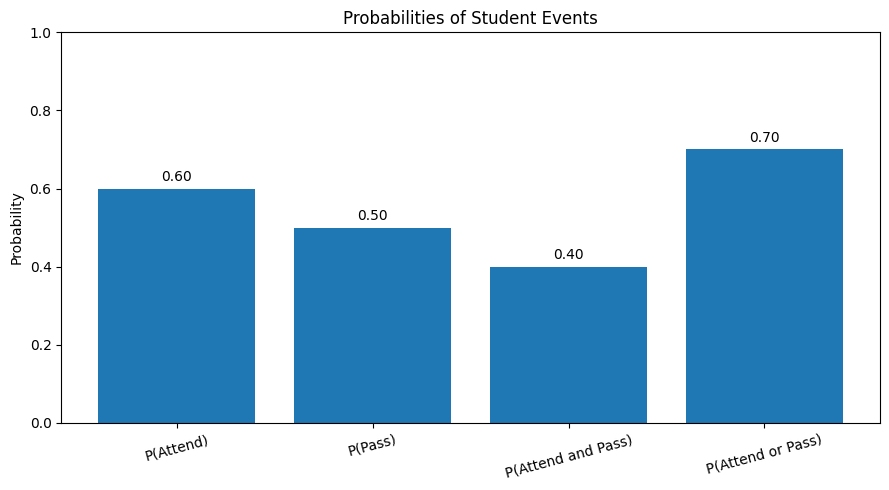

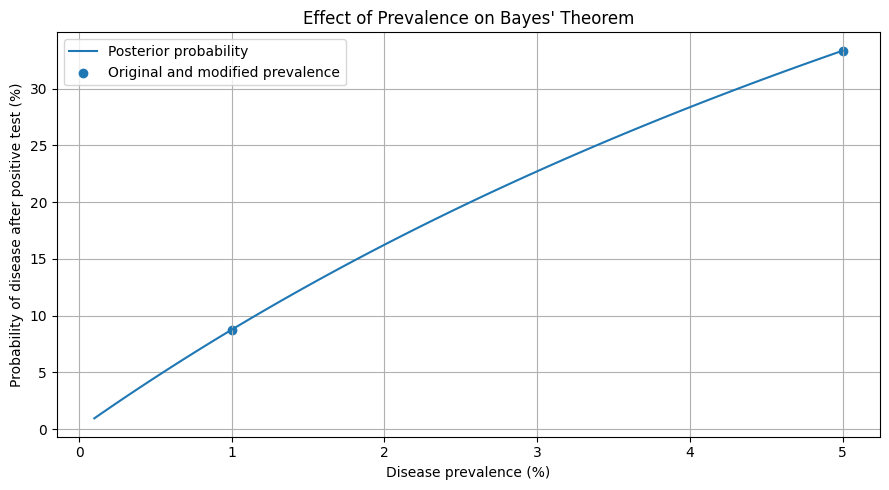

At 1% prevalence: 8.76%
At 5% prevalence: 33.33%


In [ ]:
# Experiment 7 - Exercise 6: Visualization

import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------
# Graph 1: Student event probabilities
# -----------------------------------

labels = [
    "P(Attend)",
    "P(Pass)",
    "P(Attend and Pass)",
    "P(Attend or Pass)"
]

probabilities = [
    P_A,
    P_B,
    P_A_and_B,
    P_A_or_B
]

plt.figure(figsize=(9, 5))
bars = plt.bar(labels, probabilities)

plt.title("Probabilities of Student Events")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.xticks(rotation=15)

for bar, value in zip(bars, probabilities):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# -----------------------------------
# Graph 2: Effect of disease prevalence
# -----------------------------------

prevalences = np.linspace(0.001, 0.05, 100)

sensitivity = 0.95
specificity = 0.90
false_positive_rate = 1 - specificity

posterior_probabilities = (
    sensitivity * prevalences
    / (
        sensitivity * prevalences
        + false_positive_rate * (1 - prevalences)
    )
)

# Compare original prevalence (1%) with modified prevalence (5%)
def bayes_posterior(prevalence):
    numerator = sensitivity * prevalence
    denominator = numerator + false_positive_rate * (1 - prevalence)
    return numerator / denominator

original = bayes_posterior(0.01)
modified = bayes_posterior(0.05)

plt.figure(figsize=(9, 5))
plt.plot(
    prevalences * 100,
    posterior_probabilities * 100,
    label="Posterior probability"
)

plt.scatter(
    [1, 5],
    [original * 100, modified * 100],
    label="Original and modified prevalence"
)

plt.xlabel("Disease prevalence (%)")
plt.ylabel("Probability of disease after positive test (%)")
plt.title("Effect of Prevalence on Bayes' Theorem")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"At 1% prevalence: {original:.2%}")
print(f"At 5% prevalence: {modified:.2%}")